# **1. Data Preparation**

In [1]:
import os
import re
import glob
import warnings
import joblib
import pickle
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_val_score,
    RandomizedSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
from google.colab import files
import io

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset imported successfully")
print("Dataset name:", file_name)
print("Dataset shape:", df.shape)

display(df.head())

Saving used_cars.csv to used_cars.csv
Dataset imported successfully
Dataset name: used_cars.csv
Dataset shape: (4009, 12)


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [4]:
df_clean = df.copy()

df_clean["price"] = pd.to_numeric(
    df_clean["price"].astype(str)
    .str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

df_clean["milage"] = pd.to_numeric(
    df_clean["milage"].astype(str)
    .str.replace(",", "", regex=False)
    .str.extract(r"([\d.]+)", expand=False),
    errors="coerce"
)

df_clean["model_year"] = pd.to_numeric(
    df_clean["model_year"], errors="coerce"
)

df_clean = df_clean.dropna(
    subset=["price", "milage", "model_year"]
)

df_clean = df_clean[df_clean["price"] > 0]

df_clean["car_age"] = (
    2026 - df_clean["model_year"]
).clip(lower=0)

df_clean["engine_liters"] = pd.to_numeric(
    df_clean["engine"].str.extract(
        r"(\d+(?:\.\d+)?)\s*[Ll]\b", expand=False
    ),
    errors="coerce"
)

df_clean["horsepower"] = pd.to_numeric(
    df_clean["engine"].str.extract(
        r"(\d+(?:\.\d+)?)\s*HP\b",
        flags=re.IGNORECASE,
        expand=False
    ),
    errors="coerce"
)

df_clean["cylinders"] = pd.to_numeric(
    df_clean["engine"].str.extract(
        r"(\d+)\s*Cylinder", flags=re.IGNORECASE,
        expand=False
    ),
    errors="coerce"
)

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("\nRemaining missing values:")
display(df_clean.isnull().sum().sort_values(ascending=False))

print("\nCleaned data preview:")
display(df_clean.head())

print("\nPrice and mileage data types:")
print(df_clean[["price", "milage"]].dtypes)

Original shape: (4009, 12)
Cleaned shape: (4009, 16)

Remaining missing values:


,0
cylinders,945
horsepower,808
clean_title,596
engine_liters,375
fuel_type,170
accident,113
model_year,0
brand,0
ext_col,0
transmission,0



Cleaned data preview:


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,car_age,engine_liters,horsepower,cylinders
0,Ford,Utility Police Interceptor Base,2013,51000,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300,13,3.7,300.0,6.0
1,Hyundai,Palisade SEL,2021,34742,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005,5,3.8,NaN,NaN
2,Lexus,RX 350 RX 350,2022,22372,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598,4,NaN,NaN,NaN
3,INFINITI,Q50 Hybrid Sport,2015,88900,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500,11,3.5,354.0,6.0
4,Audi,Q3 45 S line Premium Plus,2021,9835,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999,5,2.0,NaN,NaN



Price and mileage data types:
price     int64
milage    int64
dtype: object


,count,mean,std,min,25%,50%,75%,max
price,4009.0,44553.190322,78710.635554,2000.00,17200.0,31000.0,49990.0,2954083.0
milage,4009.0,64717.551010,52296.599459,100.00,23044.0,52775.0,94100.0,405000.0
model_year,4009.0,2015.515590,6.104816,1974.00,2012.0,2017.0,2020.0,2024.0
car_age,4009.0,10.484410,6.104816,2.00,6.0,9.0,14.0,52.0
engine_liters,3634.0,3.709397,1.423903,0.65,2.5,3.5,4.7,8.4
horsepower,3201.0,332.206498,122.258492,70.00,248.0,310.0,400.0,1020.0
cylinders,3064.0,6.258159,1.677256,3.00,5.0,6.0,8.0,12.0


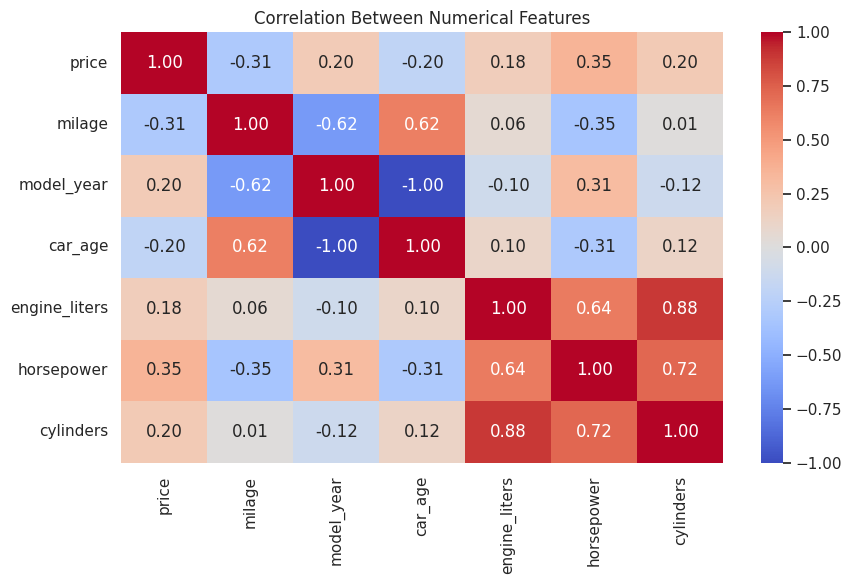

Top 10 brands by number of listings:


,count
brand,
Ford,386
BMW,375
Mercedes-Benz,315
Chevrolet,292
Porsche,201
Audi,200
Toyota,199
Lexus,163
Jeep,143



Price summary:
count    4.009000e+03
mean     4.455319e+04
std      7.871064e+04
min      2.000000e+03
25%      1.720000e+04
50%      3.100000e+04
75%      4.999000e+04
max      2.954083e+06
Name: price, dtype: float64


In [5]:
display(
    df_clean[
        ["price", "milage", "model_year",
         "car_age", "engine_liters",
         "horsepower", "cylinders"]
    ].describe().T
)

numeric_cols = [
    "price", "milage", "model_year",
    "car_age", "engine_liters",
    "horsepower", "cylinders"
]

plt.figure(figsize=(9, 6))
sns.heatmap(
    df_clean[numeric_cols].corr(),
    annot=True, cmap="coolwarm",
    fmt=".2f", center=0
)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

print("Top 10 brands by number of listings:")
display(df_clean["brand"].value_counts().head(10))

print("\nPrice summary:")
print(df_clean["price"].describe())

In [6]:
target = "price"

features = [
    "brand",
    "model",
    "car_age",
    "milage",
    "fuel_type",
    "transmission",
    "ext_col",
    "int_col",
    "accident",
    "clean_title",
    "engine_liters",
    "horsepower",
    "cylinders"
]

X = df_clean[features].copy()
y = df_clean[target].copy()

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Selected features:", features)
print("\nNumerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("\nTraining rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Training target mean:", round(y_train.mean(), 2))
print("Testing target mean:", round(y_test.mean(), 2))

Selected features: ['brand', 'model', 'car_age', 'milage', 'fuel_type', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title', 'engine_liters', 'horsepower', 'cylinders']

Numerical features: ['car_age', 'milage', 'engine_liters', 'horsepower', 'cylinders']

Categorical features: ['brand', 'model', 'fuel_type', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']

Training rows: 3207
Testing rows: 802
Training target mean: 43125.76
Testing target mean: 50261.14


In [7]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessor created successfully.")
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Preprocessor created successfully.
Numerical features: ['car_age', 'milage', 'engine_liters', 'horsepower', 'cylinders']
Categorical features: ['brand', 'model', 'fuel_type', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']


# **2. Model Development**

In [8]:
models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=10.0),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=15,
        min_samples_leaf=3,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

trained_models = {}
results = []

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    print(f"Training {name}...")

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results).sort_values(
    by="RMSE", ascending=True
).reset_index(drop=True)

display(results_df.round(4))

Training Linear Regression...
Training Ridge Regression...
Training Decision Tree...
Training Random Forest...
Training Gradient Boosting...


,Model,MAE,RMSE,R2
0,Random Forest,17192.8110,133047.0454,0.1340
1,Gradient Boosting,20170.4183,133351.7590,0.1300
2,Decision Tree,20455.8210,135396.0088,0.1031
3,Ridge Regression,22114.1622,135600.3572,0.1004
4,Linear Regression,22251.0014,138817.9961,0.0572


,brand,model,model_year,milage,price
693,Maserati,Quattroporte Base,2005,32000,2954083
229,Bugatti,Veyron 16.4 Grand Sport,2011,6330,1950995
3046,Porsche,Carrera GT Base,2005,4400,1599000
1356,Lamborghini,Aventador SVJ Base,2021,6987,749950
624,Rolls-Royce,Cullinan,2022,398,695000
979,Lamborghini,Aventador SVJ Base,2019,6929,649999
1615,Rolls-Royce,Phantom,2023,1560,599995
1508,Rolls-Royce,Phantom,2018,7585,599000
3655,Lamborghini,Aventador S Base,2018,5858,491836
1061,Dodge,Viper GTC,2017,1389,489995


Price percentiles:


,price
0.500,31000.00
0.750,49990.00
0.900,79999.00
0.950,111600.00
0.990,272713.28
0.995,398303.64
1.000,2954083.00


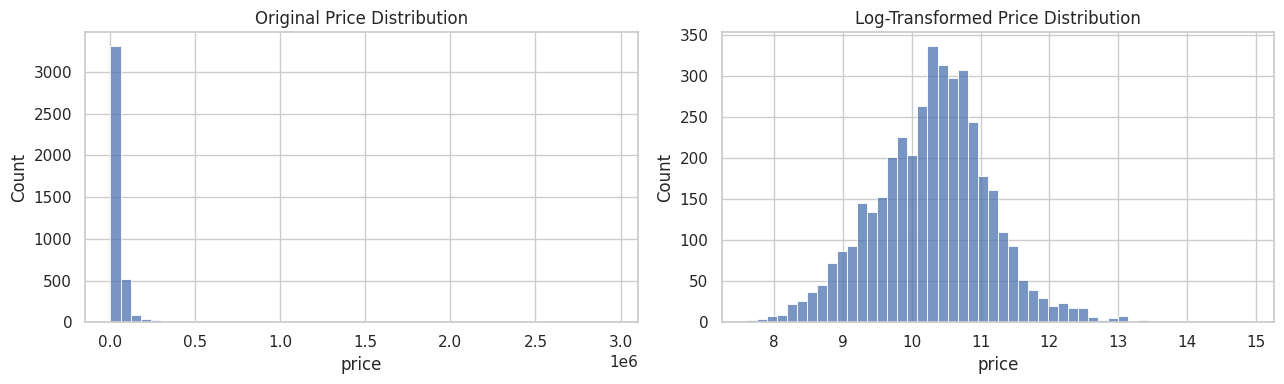

In [9]:
# Inspecting 15 most expensive listings
display(
    df_clean.nlargest(15, "price")[
        ["brand", "model", "model_year", "milage", "price"]
    ]
)

print("Price percentiles:")
display(
    df_clean["price"].quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 1.00]
    ).to_frame("price")
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df_clean["price"], bins=50, ax=axes[0])
axes[0].set_title("Original Price Distribution")

sns.histplot(np.log1p(df_clean["price"]), bins=50, ax=axes[1])
axes[1].set_title("Log-Transformed Price Distribution")

plt.tight_layout()
plt.show()

# **3. Model Optimization**

In [10]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import RandomizedSearchCV, KFold

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

log_rf = TransformedTargetRegressor(
    regressor=rf_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

param_distributions = {
    "regressor__model__n_estimators": [100, 200, 300],
    "regressor__model__max_depth": [None, 10, 20, 30],
    "regressor__model__min_samples_split": [2, 5, 10],
    "regressor__model__min_samples_leaf": [1, 2, 4],
    "regressor__model__max_features": [0.5, 0.8, 1.0]
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    estimator=log_rf,
    param_distributions=param_distributions,
    n_iter=12,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

print("Best cross-validation RMSE:", -search.best_score_)
print("\nBest parameters:")
print(search.best_params_)

tuned_model = search.best_estimator_

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best cross-validation RMSE: 29494.39358423499

Best parameters:
{'regressor__model__n_estimators': 100, 'regressor__model__min_samples_split': 5, 'regressor__model__min_samples_leaf': 1, 'regressor__model__max_features': 1.0, 'regressor__model__max_depth': 20}


In [11]:
tuned_predictions = tuned_model.predict(X_test)

tuned_mae = mean_absolute_error(y_test, tuned_predictions)
tuned_rmse = np.sqrt(
    mean_squared_error(y_test, tuned_predictions)
)
tuned_r2 = r2_score(y_test, tuned_predictions)

comparison = pd.DataFrame([
    {
        "Model": "Initial Random Forest",
        "MAE": results_df.loc[
            results_df["Model"] == "Random Forest", "MAE"
        ].iloc[0],
        "RMSE": results_df.loc[
            results_df["Model"] == "Random Forest", "RMSE"
        ].iloc[0],
        "R2": results_df.loc[
            results_df["Model"] == "Random Forest", "R2"
        ].iloc[0]
    },
    {
        "Model": "Tuned Log-Target Random Forest",
        "MAE": tuned_mae,
        "RMSE": tuned_rmse,
        "R2": tuned_r2
    }
])

display(comparison.round(4))

,Model,MAE,RMSE,R2
0,Initial Random Forest,17192.8110,133047.0454,0.1340
1,Tuned Log-Target Random Forest,17283.7055,135127.2154,0.1067


Top 15 Important Features:


,Feature,Importance
1,num__milage,0.3315
2,num__engine_liters,0.1242
29,cat__brand_Lamborghini,0.1073
50,cat__brand_Rolls-Royce,0.1020
3,num__horsepower,0.0800
0,num__car_age,0.0375
311,cat__model_Aventador SVJ Base,0.0228
17,cat__brand_Ferrari,0.0228
47,cat__brand_Porsche,0.0220
1728,cat__transmission_7-Speed Automatic with Auto-...,0.0138


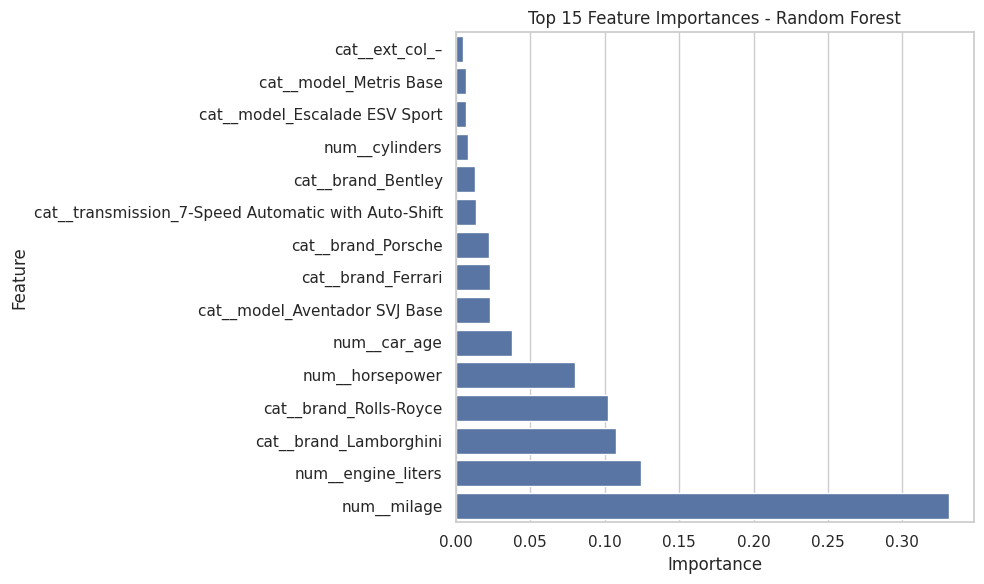

In [12]:
best_model = trained_models["Random Forest"]

fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_rf = best_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()
importances = fitted_rf.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

print("Top 15 Important Features:")
display(importance_df.head(15).round(4))

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 6))
sns.barplot(data=top_features, x="Importance", y="Feature")
plt.title("Top 15 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# **4. Saving The Best Model**

In [13]:
import joblib
import pickle

joblib.dump(best_model, "used_vehicle_price_model.joblib")

with open("used_vehicle_price_model.pkl", "wb") as file:
    pickle.dump(best_model, file)

print("Model saved successfully!")
print("1. used_vehicle_price_model.joblib")
print("2. used_vehicle_price_model.pkl")

Model saved successfully!
1. used_vehicle_price_model.joblib
2. used_vehicle_price_model.pkl


# **Bonus**

In [14]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

st.set_page_config(
    page_title="Used Vehicle Price Predictor",
    page_icon="🚘",
    layout="centered"
)

@st.cache_resource
def load_model():
    return joblib.load("used_vehicle_price_model.joblib")

model = load_model()

st.title("Used Vehicle Price Predictor")
st.write(
    "Estimate a used vehicle's price using a machine learning model. "
    "The result is an estimate, not a professional valuation."
)

st.divider()
st.subheader("Enter Vehicle Details")

# Basic vehicle details
brand = st.text_input("Brand", value="Toyota")
car_model = st.text_input("Model", value="Camry")
model_year = st.number_input(
    "Model Year", min_value=1974, max_value=2026,
    value=2020, step=1
)
mileage = st.number_input(
    "Mileage", min_value=0, max_value=1000000,
    value=50000, step=1000
)

# Additional features used during model training
fuel_type = st.selectbox(
    "Fuel Type",
    ["Gasoline", "Hybrid", "Diesel", "E85 Flex Fuel",
     "Plug-In Hybrid", "Electric", "Other", "Missing"]
)

transmission = st.text_input(
    "Transmission", value="Automatic"
)
exterior_color = st.text_input(
    "Exterior Color", value="Black"
)
interior_color = st.text_input(
    "Interior Color", value="Black"
)
accident = st.selectbox(
    "Accident History",
    ["None reported", "At least 1 accident or damage", "Missing"]
)
clean_title = st.selectbox(
    "Clean Title",
    ["Yes", "No", "Missing"]
)

st.subheader("Engine Details")
engine_liters = st.number_input(
    "Engine Size (liters)", min_value=0.0,
    max_value=15.0, value=2.5, step=0.1
)
horsepower = st.number_input(
    "Horsepower (HP)", min_value=0.0,
    max_value=2000.0, value=200.0, step=10.0
)
cylinders = st.number_input(
    "Number of Cylinders", min_value=0,
    max_value=16, value=4, step=1
)

if st.button("Predict Vehicle Price", type="primary"):
    # Match the exact feature names used during model training
    input_data = pd.DataFrame([{
        "brand": brand,
        "model": car_model,
        "car_age": max(0, 2026 - int(model_year)),
        "milage": mileage,
        "fuel_type": fuel_type,
        "transmission": transmission,
        "ext_col": exterior_color,
        "int_col": interior_color,
        "accident": (
            "None reported" if accident == "None reported"
            else "At least 1 accident or damage"
            if accident == "At least 1 accident or damage"
            else "Missing"
        ),
        "clean_title": (
            "Yes" if clean_title == "Yes"
            else "No" if clean_title == "No"
            else "Missing"
        ),
        "engine_liters": engine_liters if engine_liters > 0 else None,
        "horsepower": horsepower if horsepower > 0 else None,
        "cylinders": cylinders if cylinders > 0 else None
    }])

    try:
        prediction = model.predict(input_data)[0]
        st.success(f"Estimated Vehicle Price: ${prediction:,.2f}")
        st.caption(
            "This estimate depends on the dataset and model limitations. "
            "It should not be treated as a guaranteed market price."
        )
    except Exception as error:
        st.error(f"Prediction failed: {error}")
        st.info(
            "Check that the saved model matches the features used by this app."
        )

Writing app.py


In [15]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 27.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 60.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [16]:
import sklearn
import pandas as pd
import numpy as np
import joblib
import streamlit

with open("requirements.txt", "w") as f:
    f.write(f"streamlit=={streamlit.__version__}\n")
    f.write(f"pandas=={pd.__version__}\n")
    f.write(f"numpy=={np.__version__}\n")
    f.write(f"scikit-learn=={sklearn.__version__}\n")
    f.write(f"joblib=={joblib.__version__}\n")

print(open("requirements.txt").read())


streamlit==1.66.1
pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
joblib==1.6.0



In [17]:
import os

for filename in ["app.py", "used_vehicle_price_model.joblib", "requirements.txt"]:
    print(filename, "—", "Found" if os.path.exists(filename) else "MISSING")

app.py — Found
used_vehicle_price_model.joblib — Found
requirements.txt — Found


In [18]:
from google.colab import files
files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
from google.colab import files
files.download("used_vehicle_price_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
from google.colab import files
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>